# Regressão Linear Múltipla

Continuação de `task1.ipynb` (EDA): as variáveis constantes/redundantes removidas aqui foram identificadas nesse notebook.

In [1]:
# ============================================================
# 0. SETUP
# ============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

df = pd.read_csv("dataset_grupo_08.csv")

## Regressão Linear Múltipla (`target_regression`)

**Protocolo**
- *Holdout* 80/20 estratificado por `target_class` (`random_state=42`). O conjunto de teste só é usado para a avaliação final; **toda a escolha de variáveis/modelo é feita por validação cruzada 5-fold no treino**, para evitar fuga de informação.
- Métricas: $R^2$, MAE e RMSE (treino, CV e teste). O RMSE tem as unidades do alvo e é o critério de seleção.
- Referência (*baseline*): modelo que prevê sempre a média do treino ($R^2 \approx 0$).

**Variáveis candidatas** — removidas as identificadas na EDA como constantes/redundantes (`calcium_baseline`, `age_normalized`, `systolic_index`, `ldl_alternative`) e as discretizações exatas de contínuas (`age_level`, `bmi_level`). `target_class` **não** é usada como preditor (é outro alvo). As categóricas são codificadas com *one-hot* e `drop_first=True` para evitar multicolinearidade perfeita.

In [2]:
# ============================================================
# 1. MLR - DATA PREPARATION AND HOLDOUT
# ============================================================
from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan

RANDOM_STATE = 42
y_reg = df["target_regression"]

drop_cols = ["target_regression", "target_class",
             "calcium_baseline", "age_normalized", "systolic_index", "ldl_alternative",
             "age_level", "bmi_level"]
X_raw = df.drop(columns=drop_cols)
cat_predictors = X_raw.select_dtypes(exclude="number").columns.tolist()
X_all = pd.get_dummies(X_raw, columns=cat_predictors, drop_first=True, dtype=int)

X_train, X_test, y_train, y_test, cls_train, cls_test = train_test_split(
    X_all, y_reg, df["target_class"], test_size=0.2, random_state=RANDOM_STATE,
    stratify=df["target_class"],
)

kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

print(f"Preditores candidatos: {X_all.shape[1]} (numéricos: {X_raw.select_dtypes('number').shape[1]}, "
      f"dummies: {X_all.shape[1] - X_raw.select_dtypes('number').shape[1]})")
print(f"Treino: {X_train.shape[0]} | Teste: {X_test.shape[0]}")
print("\nDistribuição de target_class (treino vs teste, %):")
display(pd.concat([cls_train.value_counts(normalize=True).mul(100).round(1).rename("treino"),
                   cls_test.value_counts(normalize=True).mul(100).round(1).rename("teste")], axis=1))
print(f"std(target_regression): treino = {y_train.std():.2f} | teste = {y_test.std():.2f}")

Preditores candidatos: 33 (numéricos: 17, dummies: 16)
Treino: 1600 | Teste: 400

Distribuição de target_class (treino vs teste, %):


,treino,teste
target_class,,
N,49.9,50.0
HY,33.4,33.5
DI,16.7,16.5


std(target_regression): treino = 38.59 | teste = 39.34


In [3]:
# ============================================================
# 2. MLR - EVALUATION HELPERS AND BASELINES
# ============================================================
results = []

def rmse(y_true, y_pred):
    return mean_squared_error(y_true, y_pred) ** 0.5


def evaluate(name, cols, estimator=None, group=""):
    """CV 5-fold no treino + ajuste final no treino + avaliação no teste."""
    estimator = estimator if estimator is not None else LinearRegression()
    cols = list(cols)
    cv = cross_validate(
        estimator, X_train[cols], y_train, cv=kf,
        scoring={"r2": "r2", "rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error"},
    )
    estimator.fit(X_train[cols], y_train)
    p_tr, p_te = estimator.predict(X_train[cols]), estimator.predict(X_test[cols])
    row = {
        "Modelo": name, "Grupo": group, "n_features": len(cols),
        "CV R2": cv["test_r2"].mean(), "CV RMSE": -cv["test_rmse"].mean(), "CV RMSE std": cv["test_rmse"].std(),
        "Train R2": r2_score(y_train, p_tr), "Train RMSE": rmse(y_train, p_tr),
        "Test R2": r2_score(y_test, p_te), "Test MAE": mean_absolute_error(y_test, p_te),
        "Test RMSE": rmse(y_test, p_te),
        "features": cols,
    }
    results.append(row)
    return row


# Baseline: prever a média do treino
evaluate("Baseline (média)", X_train.columns[:1], estimator=DummyRegressor(strategy="mean"), group="baseline")

# Referência: melhor variável isolada (menor RMSE em CV)
single = {c: -cross_validate(LinearRegression(), X_train[[c]], y_train, cv=kf,
                             scoring="neg_root_mean_squared_error")["test_score"].mean()
          for c in X_train.columns}
best_single = min(single, key=single.get)
evaluate(f"Regressão simples ({best_single})", [best_single], group="referência")

print("Top 5 variáveis isoladas por CV RMSE (menor é melhor):")
display(pd.Series(single, name="CV RMSE").sort_values().head(5).round(3).to_frame())

Top 5 variáveis isoladas por CV RMSE (menor é melhor):


,CV RMSE
HbA1c_level,38.369
employment_status_Retired,38.485
bmi,38.499
sleep_hours,38.518
blood_pressure,38.532


### Combinações de variáveis por grupos clínicos

Primeiro testam-se grupos com significado clínico (isolados e combinados), para perceber que tipo de informação contribui para prever `target_regression`.

In [4]:
# ============================================================
# 3. MLR - FEATURE GROUPS
# ============================================================
def cols_with(*prefixes):
    return [c for c in X_all.columns if any(c == p or c.startswith(p + "_") for p in prefixes)]

feature_groups = {
    "Demográficas": cols_with("age", "gender", "education_level", "employment_status"),
    "Antropométricas": cols_with("bmi"),
    "Estilo de vida": cols_with("smoking", "physical_activity", "stress_level", "sleep_hours",
                                "alcohol_intake", "salt_intake", "sugar_consumption"),
    "Glicémico/lipídico": cols_with("HbA1c_level", "cholesterol", "triglycerides", "hdl", "ldl",
                                    "low_hdl_cholesterol", "high_ldl_cholesterol"),
    "Inflamação/outros": cols_with("crp_level", "homocysteine_level", "plasma_value", "family_history"),
    "Hemodinâmicas": cols_with("blood_pressure", "systolic_bp", "diastolic_bp", "heart_rate"),
}

assert sorted(sum(feature_groups.values(), [])) == sorted(X_all.columns), "grupos têm de cobrir todas as colunas"

for gname, gcols in feature_groups.items():
    evaluate(f"Grupo: {gname}", gcols, group="grupo")

clinical = sum([feature_groups[g] for g in ["Antropométricas", "Glicémico/lipídico", "Inflamação/outros", "Hemodinâmicas"]], [])
evaluate("Grupos clínicos combinados", clinical, group="combinação")
evaluate("Todas as variáveis candidatas", X_all.columns, group="combinação")

group_table = (pd.DataFrame(results).query("Grupo in ['baseline','referência','grupo','combinação']")
               [["Modelo", "n_features", "CV R2", "CV RMSE", "CV RMSE std", "Train R2", "Test R2", "Test RMSE"]])
display(group_table.round(4).reset_index(drop=True))

,Modelo,n_features,CV R2,CV RMSE,CV RMSE std,Train R2,Test R2,Test RMSE
0,Baseline (média),1,-0.0039,38.5574,1.8411,0.0000,-0.0048,39.3808
1,Regressão simples (HbA1c_level),1,0.0052,38.3686,1.5996,0.0118,0.0110,39.0704
2,Grupo: Demográficas,6,-0.0043,38.5617,1.7768,0.0058,-0.0036,39.3568
3,Grupo: Antropométricas,1,-0.0010,38.4991,1.7794,0.0037,-0.0096,39.4741
4,Grupo: Estilo de vida,11,-0.0123,38.7193,1.8437,0.0060,-0.0060,39.4034
5,Grupo: Glicémico/lipídico,7,0.0037,38.3926,1.5191,0.0153,-0.0011,39.3085
6,Grupo: Inflamação/outros,4,-0.0054,38.5899,1.8936,0.0029,-0.0147,39.5730
7,Grupo: Hemodinâmicas,4,-0.0034,38.5478,1.8389,0.0042,-0.0092,39.4669
8,Grupos clínicos combinados,16,0.0062,38.3422,1.5017,0.0265,-0.0212,39.7003
9,Todas as variáveis candidatas,33,-0.0048,38.5413,1.3401,0.0411,-0.0332,39.9330


### Seleção automática de variáveis

Três estratégias, todas baseadas apenas no treino:
- **Forward selection** (`SequentialFeatureSelector`) com critério RMSE em CV 5-fold e paragem quando o ganho é inferior a `tol`.
- **Backward selection** idem, partindo de todas as variáveis.
- **Eliminação retroativa por p-value** (OLS, $\alpha = 0.05$), removendo em cada passo a variável menos significativa.

In [5]:
# ============================================================
# 4. MLR - AUTOMATIC FEATURE SELECTION
# ============================================================
def sfs_select(direction, tol=1e-3):
    sfs = SequentialFeatureSelector(
        LinearRegression(), direction=direction, n_features_to_select="auto", tol=tol,
        cv=kf, scoring="neg_root_mean_squared_error", n_jobs=-1,
    ).fit(X_train, y_train)
    return list(X_train.columns[sfs.get_support()])


def backward_pvalue(alpha=0.05):
    cols = list(X_train.columns)
    while True:
        fit = sm.OLS(y_train, sm.add_constant(X_train[cols])).fit()
        pvals = fit.pvalues.drop("const")
        worst = pvals.idxmax()
        if pvals[worst] <= alpha or len(cols) == 1:
            return cols
        cols.remove(worst)


sel_forward = sfs_select("forward")
sel_backward = sfs_select("backward")
sel_pvalue = backward_pvalue(0.05)

evaluate("Forward selection (CV RMSE)", sel_forward, group="seleção")
evaluate("Backward selection (CV RMSE)", sel_backward, group="seleção")
evaluate("Eliminação por p-value (alpha=0.05)", sel_pvalue, group="seleção")

for name, cols in [("Forward", sel_forward), ("Backward", sel_backward), ("p-value", sel_pvalue)]:
    print(f"{name} ({len(cols)}): {cols}\n")

Forward (14): ['bmi', 'HbA1c_level', 'sleep_hours', 'blood_pressure', 'homocysteine_level', 'systolic_bp', 'diastolic_bp', 'plasma_value', 'smoking_Never', 'stress_level_Medium', 'low_hdl_cholesterol_Yes', 'high_ldl_cholesterol_Yes', 'employment_status_Retired', 'employment_status_Unemployed']

Backward (14): ['bmi', 'HbA1c_level', 'sleep_hours', 'blood_pressure', 'homocysteine_level', 'systolic_bp', 'diastolic_bp', 'plasma_value', 'smoking_Never', 'stress_level_Medium', 'low_hdl_cholesterol_Yes', 'high_ldl_cholesterol_Yes', 'employment_status_Retired', 'employment_status_Unemployed']

p-value (5): ['bmi', 'HbA1c_level', 'sleep_hours', 'blood_pressure', 'employment_status_Retired']



,Modelo,n_features,CV R2,CV RMSE,CV RMSE std,Train R2,Train RMSE,Test R2,Test MAE,Test RMSE
0,Forward selection (CV RMSE),14,0.0196,38.0878,1.5568,0.0346,37.9046,-0.0273,32.5363,39.8193
1,Backward selection (CV RMSE),14,0.0196,38.0878,1.5568,0.0346,37.9046,-0.0273,32.5363,39.8193
2,Eliminação por p-value (alpha=0.05),5,0.0159,38.1600,1.5384,0.0238,38.1151,-0.0043,32.0682,39.3713
3,Grupos clínicos combinados,16,0.0062,38.3422,1.5017,0.0265,38.0630,-0.0212,32.4154,39.7003
4,Regressão simples (HbA1c_level),1,0.0052,38.3686,1.5996,0.0118,38.3495,0.0110,31.8372,39.0704
5,Grupo: Glicémico/lipídico,7,0.0037,38.3926,1.5191,0.0153,38.2809,-0.0011,31.9563,39.3085
6,Grupo: Antropométricas,1,-0.0010,38.4991,1.7794,0.0037,38.5054,-0.0096,32.0767,39.4741
7,Todas as variáveis candidatas,33,-0.0048,38.5413,1.3401,0.0411,37.7762,-0.0332,32.6063,39.9330
8,Grupo: Hemodinâmicas,4,-0.0034,38.5478,1.8389,0.0042,38.4956,-0.0092,32.1356,39.4669
9,Baseline (média),1,-0.0039,38.5574,1.8411,0.0000,38.5775,-0.0048,31.9918,39.3808


Melhor MLR segundo a CV no treino: Forward selection (CV RMSE) (14 variáveis)
  CV RMSE = 38.088 +- 1.557 | baseline CV RMSE = 38.557


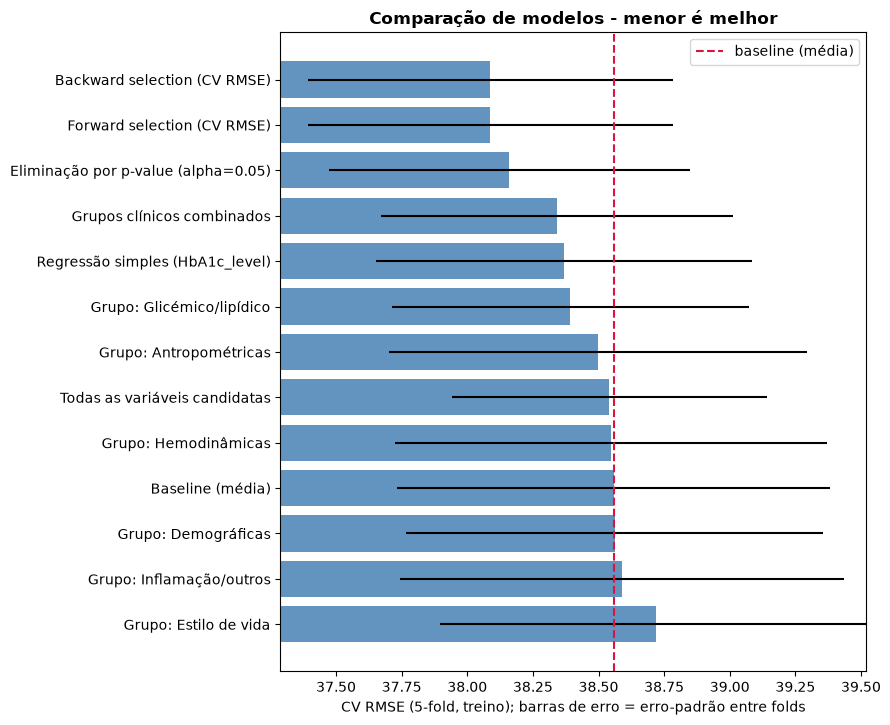

In [6]:
# ============================================================
# 5. MLR - MODEL COMPARISON AND SELECTION (CRITERION: CV RMSE ON TRAIN)
# ============================================================
res = pd.DataFrame(results)
cols_show = ["Modelo", "n_features", "CV R2", "CV RMSE", "CV RMSE std",
             "Train R2", "Train RMSE", "Test R2", "Test MAE", "Test RMSE"]
display(res.sort_values("CV RMSE")[cols_show].round(4).reset_index(drop=True))

mlr_candidates = res[res["Grupo"].isin(["grupo", "combinação", "seleção"])]
best_row = mlr_candidates.sort_values("CV RMSE").iloc[0]
best_name, best_cols = best_row["Modelo"], best_row["features"]
print(f"Melhor MLR segundo a CV no treino: {best_name} ({len(best_cols)} variáveis)")
print(f"  CV RMSE = {best_row['CV RMSE']:.3f} +- {best_row['CV RMSE std']:.3f} "
      f"| baseline CV RMSE = {res.loc[res['Grupo'] == 'baseline', 'CV RMSE'].iloc[0]:.3f}")

fig, ax = plt.subplots(figsize=(9, 0.45 * len(res) + 1.5))
plot_df = res.sort_values("CV RMSE", ascending=False)
ax.barh(plot_df["Modelo"], plot_df["CV RMSE"], xerr=plot_df["CV RMSE std"] / np.sqrt(kf.get_n_splits()),
        color="steelblue", alpha=0.85)
ax.axvline(res.loc[res["Grupo"] == "baseline", "CV RMSE"].iloc[0], color="crimson", ls="--", label="baseline (média)")
ax.set_xlim(plot_df["CV RMSE"].min() - 0.8, plot_df["CV RMSE"].max() + 0.8)
ax.set_xlabel("CV RMSE (5-fold, treino); barras de erro = erro-padrão entre folds")
ax.set_title("Comparação de modelos - menor é melhor", fontweight="bold")
ax.legend()
plt.tight_layout()
plt.show()

### Validação cruzada aninhada (estimativa não enviesada do procedimento de seleção)

O RMSE em CV das variáveis escolhidas por *forward/backward selection* é **otimista**: as mesmas *folds* serviram para escolher as variáveis e para as avaliar. Para estimar o desempenho real do *procedimento* (seleção + ajuste), a seleção é repetida dentro de cada *fold* externo, usando apenas os dados de treino dessa *fold*.

In [7]:
# ============================================================
# 5.1 MLR - NESTED CV: UNBIASED ESTIMATE OF "FORWARD SELECTION + OLS"
# ============================================================
from sklearn.pipeline import Pipeline

inner_cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
outer_cv = KFold(n_splits=5, shuffle=True, random_state=7)
scoring = {"r2": "r2", "rmse": "neg_root_mean_squared_error"}

forward_pipe = Pipeline([
    ("select", SequentialFeatureSelector(LinearRegression(), direction="forward", n_features_to_select="auto",
                                         tol=1e-3, cv=inner_cv, scoring="neg_root_mean_squared_error")),
    ("ols", LinearRegression()),
])

nested_rows = {}
for label, est in [("Forward selection + OLS (aninhada)", forward_pipe),
                   ("Todas as variáveis + OLS", LinearRegression()),
                   ("Baseline (média)", DummyRegressor())]:
    cv_res = cross_validate(est, X_train, y_train, cv=outer_cv, scoring=scoring, n_jobs=-1)
    nested_rows[label] = {"CV R2": cv_res["test_r2"].mean(), "CV RMSE": -cv_res["test_rmse"].mean(),
                          "CV RMSE std": cv_res["test_rmse"].std()}

display(pd.DataFrame(nested_rows).T.round(4))

,CV R2,CV RMSE,CV RMSE std
Forward selection + OLS (aninhada),-0.0116,38.6013,0.9187
Todas as variáveis + OLS,-0.0151,38.6672,1.1197
Baseline (média),-0.0152,38.6726,0.9136


### Modelo final: coeficientes, multicolinearidade e diagnóstico dos resíduos

Ajusta-se por OLS (`statsmodels`) o modelo escolhido para obter coeficientes, p-values e intervalos de confiança, VIF e verificar os pressupostos (linearidade, homocedasticidade, normalidade dos resíduos, observações influentes).

In [8]:
# ============================================================
# 6. MLR - FINAL MODEL (OLS SUMMARY, VIF)
# ============================================================
best_cols = list(best_cols)
ols = sm.OLS(y_train, sm.add_constant(X_train[best_cols])).fit()
print(ols.summary())

# Coeficientes padronizados: efeito (em desvios-padrão do alvo) de +1 desvio-padrão na variável
coef = pd.DataFrame({
    "coef": ols.params.drop("const"),
    "std_err": ols.bse.drop("const"),
    "p_value": ols.pvalues.drop("const"),
})
coef["beta_padronizado"] = coef["coef"] * X_train[best_cols].std() / y_train.std()
display(coef.sort_values("p_value").round(4))

vif = pd.Series(
    [variance_inflation_factor(sm.add_constant(X_train[best_cols]).values, i + 1) for i in range(len(best_cols))],
    index=best_cols, name="VIF",
).sort_values(ascending=False)
print("VIF (regra prática: > 5 sugere colinearidade relevante, > 10 problemática):")
display(vif.round(2).to_frame())

                            OLS Regression Results                            
Dep. Variable:      target_regression   R-squared:                       0.035
Model:                            OLS   Adj. R-squared:                  0.026
Method:                 Least Squares   F-statistic:                     4.055
Date:                Tue, 20 Oct 2026   Prob (F-statistic):           5.86e-07
Time:                        19:42:25   Log-Likelihood:                -8086.4
No. Observations:                1600   AIC:                         1.620e+04
Df Residuals:                    1585   BIC:                         1.628e+04
Df Model:                          14                                         
Covariance Type:            nonrobust                                         
                                   coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------
const           

,coef,std_err,p_value,beta_padronizado
HbA1c_level,4.6113,1.0756,0.0000,0.1068
bmi,0.3748,0.1354,0.0057,0.0699
employment_status_Retired,-5.8253,2.3873,0.0148,-0.0718
sleep_hours,1.6907,0.7115,0.0176,0.0593
blood_pressure,0.6226,0.2770,0.0248,0.0568
diastolic_bp,0.1466,0.0762,0.0545,0.0477
low_hdl_cholesterol_Yes,-4.3878,2.4153,0.0695,-0.0463
plasma_value,-10.4906,6.3805,0.1003,-0.0408
stress_level_Medium,-3.3685,2.1030,0.1094,-0.0402
homocysteine_level,-1.4807,1.0225,0.1478,-0.0362


VIF (regra prática: > 5 sugere colinearidade relevante, > 10 problemática):


,VIF
employment_status_Retired,1.42
employment_status_Unemployed,1.40
low_hdl_cholesterol_Yes,1.07
blood_pressure,1.05
bmi,1.05
smoking_Never,1.04
stress_level_Medium,1.03
homocysteine_level,1.03
high_ldl_cholesterol_Yes,1.02
sleep_hours,1.02


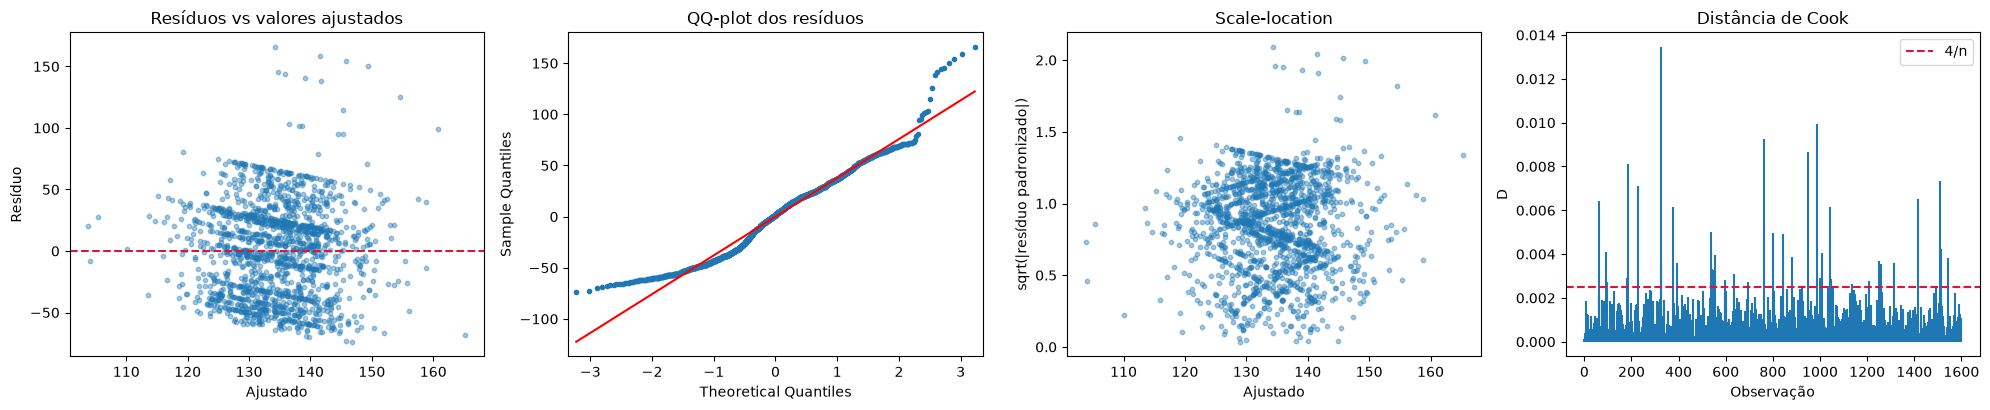

Breusch-Pagan (homocedasticidade): LM = 31.59, p = 0.0046
Shapiro-Wilk (normalidade dos resíduos): W = 0.9692, p = 5.561e-18
Assimetria dos resíduos: 0.359 | curtose excesso: 0.122
Observações com Cook's D > 4/n: 40 (2.5%) | max D = 0.013


In [9]:
# ============================================================
# 7. MLR - RESIDUAL DIAGNOSTICS
# ============================================================
resid = ols.resid
fitted = ols.fittedvalues
influence = ols.get_influence()
cooks = influence.cooks_distance[0]

fig, axes = plt.subplots(1, 4, figsize=(20, 4.2))

axes[0].scatter(fitted, resid, s=10, alpha=0.4)
axes[0].axhline(0, color="crimson", ls="--")
axes[0].set(title="Resíduos vs valores ajustados", xlabel="Ajustado", ylabel="Resíduo")

sm.qqplot(resid, line="s", ax=axes[1], markersize=3)
axes[1].set_title("QQ-plot dos resíduos")

axes[2].scatter(fitted, np.sqrt(np.abs(resid / resid.std())), s=10, alpha=0.4)
axes[2].set(title="Scale-location", xlabel="Ajustado", ylabel="sqrt(|resíduo padronizado|)")

axes[3].stem(np.arange(len(cooks)), cooks, markerfmt=" ", basefmt=" ")
axes[3].axhline(4 / len(cooks), color="crimson", ls="--", label="4/n")
axes[3].set(title="Distância de Cook", xlabel="Observação", ylabel="D")
axes[3].legend()
plt.tight_layout()
plt.show()

bp_stat, bp_p, _, _ = het_breuschpagan(resid, ols.model.exog)
sh_stat, sh_p = stats.shapiro(resid)
print(f"Breusch-Pagan (homocedasticidade): LM = {bp_stat:.2f}, p = {bp_p:.4f}")
print(f"Shapiro-Wilk (normalidade dos resíduos): W = {sh_stat:.4f}, p = {sh_p:.4g}")
print(f"Assimetria dos resíduos: {stats.skew(resid):.3f} | curtose excesso: {stats.kurtosis(resid):.3f}")
print(f"Observações com Cook's D > 4/n: {(cooks > 4 / len(cooks)).sum()} ({(cooks > 4 / len(cooks)).mean():.1%}) "
      f"| max D = {cooks.max():.3f}")

Alvo > 200: 18 obs. no treino, 6 no teste


,R2,RMSE
Treino sem alvo>200 -> teste completo,-0.0301,39.8736
Treino sem alvo>200 -> teste sem alvo>200,-0.0498,36.2186
Baseline (média) sem alvo>200 -> teste sem alvo>200,-0.0093,35.5126


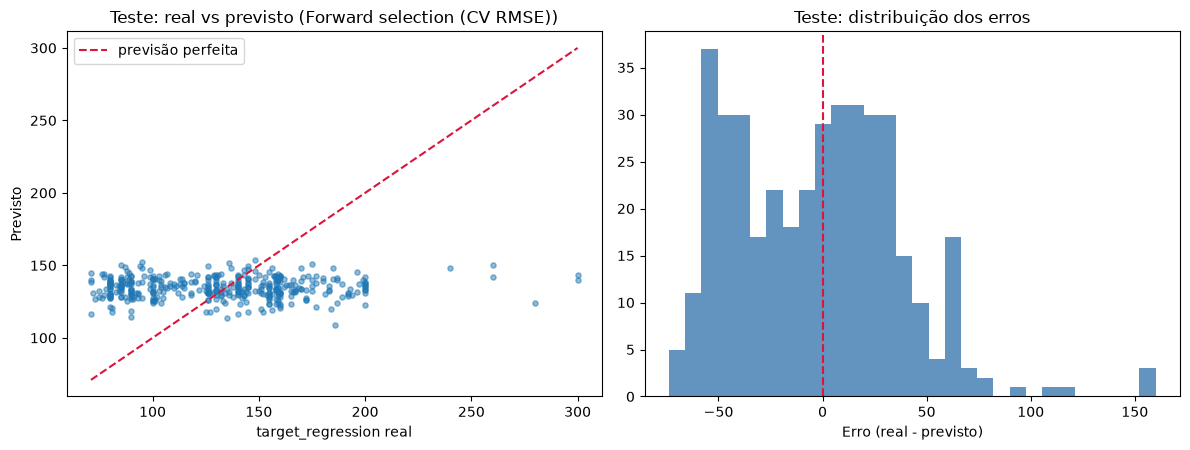

Avaliação final no conjunto de teste (holdout):


,R2,MAE,RMSE
MLR final (14 variáveis),-0.0273,32.5363,39.8193
Baseline (média),-0.0048,31.9918,39.3808


In [10]:
# ============================================================
# 8. MLR - SENSITIVITY TO OUTLIERS IN TARGET (> 200) AND FINAL TEST EVALUATION
# ============================================================
final_model = LinearRegression().fit(X_train[best_cols], y_train)
pred_test = final_model.predict(X_test[best_cols])

# Sensibilidade: remover do treino os valores de alvo > 200 (poucos, quase todos da classe DI)
mask_tr = y_train <= 200
mask_te = y_test <= 200
model_no_out = LinearRegression().fit(X_train.loc[mask_tr, best_cols], y_train[mask_tr])
baseline_no_out = DummyRegressor().fit(X_train.loc[mask_tr, best_cols], y_train[mask_tr])

sens = pd.DataFrame({
    "Treino sem alvo>200 -> teste completo": [r2_score(y_test, model_no_out.predict(X_test[best_cols])),
                                              rmse(y_test, model_no_out.predict(X_test[best_cols]))],
    "Treino sem alvo>200 -> teste sem alvo>200": [r2_score(y_test[mask_te], model_no_out.predict(X_test.loc[mask_te, best_cols])),
                                                  rmse(y_test[mask_te], model_no_out.predict(X_test.loc[mask_te, best_cols]))],
    "Baseline (média) sem alvo>200 -> teste sem alvo>200": [r2_score(y_test[mask_te], baseline_no_out.predict(X_test.loc[mask_te, best_cols])),
                                                            rmse(y_test[mask_te], baseline_no_out.predict(X_test.loc[mask_te, best_cols]))],
}, index=["R2", "RMSE"]).T
print(f"Alvo > 200: {(~mask_tr).sum()} obs. no treino, {(~mask_te).sum()} no teste")
display(sens.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
axes[0].scatter(y_test, pred_test, s=14, alpha=0.5)
lims = [y_test.min(), y_test.max()]
axes[0].plot(lims, lims, color="crimson", ls="--", label="previsão perfeita")
axes[0].set(title=f"Teste: real vs previsto ({best_name})", xlabel="target_regression real", ylabel="Previsto")
axes[0].legend()

axes[1].hist(y_test - pred_test, bins=30, color="steelblue", alpha=0.85)
axes[1].axvline(0, color="crimson", ls="--")
axes[1].set(title="Teste: distribuição dos erros", xlabel="Erro (real - previsto)")
plt.tight_layout()
plt.show()

final_summary = pd.DataFrame({
    "R2": [r2_score(y_test, pred_test), r2_score(y_test, DummyRegressor().fit(X_train, y_train).predict(X_test))],
    "MAE": [mean_absolute_error(y_test, pred_test), mean_absolute_error(y_test, DummyRegressor().fit(X_train, y_train).predict(X_test))],
    "RMSE": [rmse(y_test, pred_test), rmse(y_test, DummyRegressor().fit(X_train, y_train).predict(X_test))],
}, index=[f"MLR final ({len(best_cols)} variáveis)", "Baseline (média)"])
print("Avaliação final no conjunto de teste (holdout):")
display(final_summary.round(4))

In [11]:
# ============================================================
# 9. MLR - IS THE TEST DIFFERENCE vs BASELINE DISTINGUISHABLE FROM ZERO? (PAIRED BOOTSTRAP)
# ============================================================
rng = np.random.default_rng(RANDOM_STATE)
base_pred = DummyRegressor().fit(X_train, y_train).predict(X_test)
err_mlr = (y_test.values - pred_test) ** 2
err_base = (y_test.values - base_pred) ** 2

diffs = []
for _ in range(2000):
    idx = rng.integers(0, len(y_test), len(y_test))
    diffs.append(np.sqrt(err_mlr[idx].mean()) - np.sqrt(err_base[idx].mean()))
lo, hi = np.percentile(diffs, [2.5, 97.5])

print(f"RMSE(MLR) - RMSE(baseline) no teste: {np.sqrt(err_mlr.mean()) - np.sqrt(err_base.mean()):+.3f} "
      f"| IC 95% bootstrap: [{lo:+.3f}, {hi:+.3f}]")
print("Se o intervalo inclui 0, não há evidência de que o MLR preveja melhor do que a média.")

RMSE(MLR) - RMSE(baseline) no teste: +0.438 | IC 95% bootstrap: [-0.313, +1.221]
Se o intervalo inclui 0, não há evidência de que o MLR preveja melhor do que a média.


In [12]:
# ============================================================
# 10. SANITY CHECK - IS THERE NON-LINEAR SIGNAL THAT OLS CANNOT CAPTURE? (CV ON TRAIN)
# ============================================================
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

nonlinear = {
    "Random Forest (min_samples_leaf=10)": RandomForestRegressor(n_estimators=300, min_samples_leaf=10,
                                                                 random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting (depth=2)": GradientBoostingRegressor(max_depth=2, n_estimators=100, learning_rate=0.05,
                                                             random_state=RANDOM_STATE),
}
rows = {}
for label, est in nonlinear.items():
    cv_res = cross_validate(est, X_train, y_train, cv=kf, scoring=scoring)
    rows[label] = {"CV R2": cv_res["test_r2"].mean(), "CV RMSE": -cv_res["test_rmse"].mean()}
display(pd.DataFrame(rows).T.round(4))

,CV R2,CV RMSE
Random Forest (min_samples_leaf=10),-0.0029,38.5022
Gradient Boosting (depth=2),-0.0017,38.4862


## Conclusões

### Regressão linear múltipla
- Com a validação cruzada no treino, o *forward/backward selection* escolheu 14 variáveis (CV RMSE ≈ 38.09 vs 38.56 do *baseline*), mas essa melhoria **não se confirma**: na CV aninhada (seleção repetida dentro de cada *fold*) o procedimento fica ao nível do *baseline* (RMSE ≈ 38.60 vs 38.67), e no teste o MLR final tem $R^2 \approx -0.03$ (RMSE 39.82 vs 39.38 do *baseline*), com diferença não distinguível de zero (IC 95% bootstrap inclui 0).
- Usar **todas** as variáveis candidatas é pior do que usar um subconjunto (CV $R^2 \approx 0$, treino 0.04 vs teste negativo): sobreajuste. O modelo parcimonioso por p-value (5 variáveis: `bmi`, `HbA1c_level`, `sleep_hours`, `blood_pressure`, `employment_status_Retired`) iguala o *baseline* no teste ($R^2 \approx 0$).
- O sinal dominante é `HbA1c_level` (≈ +4.6 unidades de `target_regression` por unidade de HbA1c; β padronizado ≈ 0.11), seguido de `bmi`, `sleep_hours`, `blood_pressure` e `employment_status_Retired`, todos com efeitos pequenos. Não há multicolinearidade (VIF < 1.5).
- **Diagnóstico**: resíduos com ligeira assimetria positiva (outliers do alvo > 200), heterocedasticidade ligeira (Breusch-Pagan p ≈ 0.005) e nenhuma observação com influência relevante (max D de Cook ≈ 0.013). Remover os alvos > 200 não altera as conclusões.
- **Leitura final**: o alvo `target_regression` é, nestes dados, quase imprevisível a partir das *features* com um modelo linear (o RMSE de ≈ 38–39 é praticamente o desvio-padrão do alvo). Mesmo modelos não lineares (*random forest*/*gradient boosting*, ver secção 10) ficam com $R^2$ de CV próximo de 0, o que aponta para falta de sinal nos dados e não para uma limitação do modelo linear. A regressão linear simples com `HbA1c_level` é a referência razoável a comparar com o MLR.

> Os valores citados correspondem à execução com `random_state=42`; atualizar o texto se a partição ou os dados mudarem.